# Canny Kenar Dedektörü

INF605, Grup 10

Bu notebook'ta Canny algoritmasını adım adım yazıyoruz. Şimdilik sadece ilk adım olan Gauss ile yumuşatma var.

Kenarları bulmak için türev alacağız ve türev gürültüyü de büyütüyor. Bu yüzden önce resmi biraz bulanıklaştırıyoruz, böylece gürültüden kaynaklanan sahte kenarlar azalıyor.

Gradyan, non-maximum suppression ve histerezis adımları sonraki haftalarda eklenecek.

In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt

sys.path.append('../src')

from gaussian import load_image, gaussian_kernel, gaussian_smooth

## Test görüntülerini yükleme

İki standart test görüntüsü kullanıyoruz: `cameraman` ve `coins`. İkisini de scikit-image'ın örnek verilerinden aldık, `images` klasöründeler.

In [2]:
kameraman = load_image('../images/cameraman.png')
paralar = load_image('../images/coins.png')

print('cameraman boyutu:', kameraman.shape, kameraman.dtype)
print('coins boyutu:', paralar.shape, paralar.dtype)

cameraman boyutu: (512, 512) uint8
coins boyutu: (303, 384) uint8


## Gauss kerneli

Kerneldeki her değer şu formülle hesaplanıyor:

$$G(x,y) = e^{-\frac{x^2+y^2}{2\sigma^2}}$$

Sonra bütün değerleri toplama bölüyoruz, böylece toplam 1 oluyor ve resmin parlaklığı değişmiyor. Kernelin boyutu sigmaya göre ayarlanıyor (yarıçap = 3 * sigma).

sigma=1 için kernel boyutu: (7, 7)  toplam: 1.0
sigma=2 için kernel boyutu: (13, 13)  toplam: 1.0


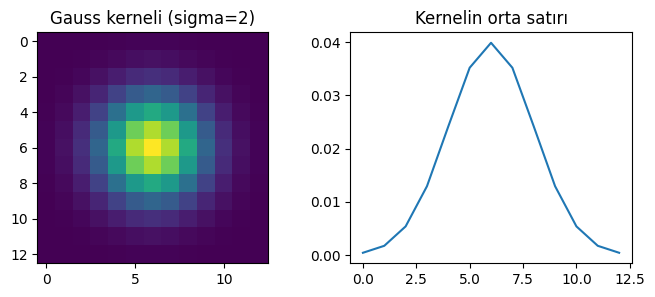

In [3]:
k1 = gaussian_kernel(1)
k2 = gaussian_kernel(2)
print('sigma=1 için kernel boyutu:', k1.shape, ' toplam:', k1.sum())
print('sigma=2 için kernel boyutu:', k2.shape, ' toplam:', k2.sum())

plt.figure(figsize=(8, 3))
plt.subplot(1, 2, 1)
plt.imshow(k2)
plt.title('Gauss kerneli (sigma=2)')
plt.subplot(1, 2, 2)
plt.plot(k2[k2.shape[0] // 2])
plt.title('Kernelin orta satırı')
plt.show()

## Yumuşatma

Kerneli resmin üzerinde gezdirmek için `cv2.filter2D` ile konvolüsyon yapıyoruz.

Farklı sigma değerlerini deneyelim:

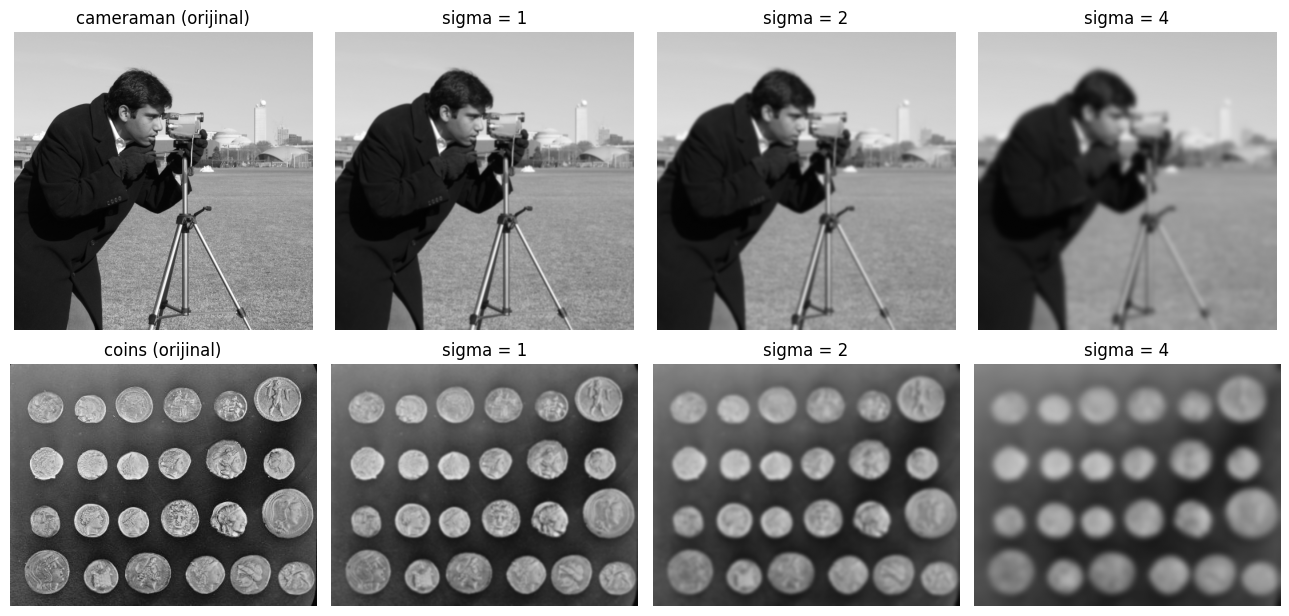

In [4]:
sigmalar = [1, 2, 4]

plt.figure(figsize=(13, 6.5))

# üst satır: cameraman
plt.subplot(2, 4, 1)
plt.imshow(kameraman, cmap='gray', vmin=0, vmax=255)
plt.title('cameraman (orijinal)')
plt.axis('off')
for i in range(len(sigmalar)):
    plt.subplot(2, 4, i + 2)
    plt.imshow(gaussian_smooth(kameraman, sigmalar[i]), cmap='gray', vmin=0, vmax=255)
    plt.title('sigma = ' + str(sigmalar[i]))
    plt.axis('off')

# alt satır: coins
plt.subplot(2, 4, 5)
plt.imshow(paralar, cmap='gray', vmin=0, vmax=255)
plt.title('coins (orijinal)')
plt.axis('off')
for i in range(len(sigmalar)):
    plt.subplot(2, 4, i + 6)
    plt.imshow(gaussian_smooth(paralar, sigmalar[i]), cmap='gray', vmin=0, vmax=255)
    plt.title('sigma = ' + str(sigmalar[i]))
    plt.axis('off')

plt.tight_layout()
plt.show()

Sigma büyüdükçe gürültü ve çimenler gibi ince detaylar kayboluyor ama kenarlar da bulanıklaşıyor. Canny de makalesinde gürültüyü azaltmakla kenarın yerini tam bulmanın birbirine ters düştüğünü anlatıyor. Sigmanın kenar haritasına etkisini algoritmanın tamamı bitince deneyeceğiz.

## Basit kontroller

Kodun mantıklı çalışıp çalışmadığını birkaç basit testle kontrol ediyoruz.

In [5]:
sonuc = gaussian_smooth(kameraman, 1)

print('Kernel toplamı 1 mi?', np.isclose(gaussian_kernel(1).sum(), 1))

print('Boyut aynı mı?', sonuc.shape == kameraman.shape)

print('Hatalı değer yok mu?', np.all(np.isfinite(sonuc)))

# her yeri aynı renk olan resim yumuşatılınca değişmemeli
duz = np.ones((20, 20)) * 128
print('Düz resim aynı kaldı mı?', np.allclose(gaussian_smooth(duz, 2), 128))

print('Değişim azaldı mı?', sonuc.std() < kameraman.std())

Kernel toplamı 1 mi? True
Boyut aynı mı? True
Hatalı değer yok mu? True
Düz resim aynı kaldı mı? True
Değişim azaldı mı? True
